# Telco churn EDA
Short: churn rate, key drivers, correlations. Uses validated raw data.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
import matplotlib.pyplot as plt
from src.config import load_params
from src.data.validate import load_raw, validate
df = validate(load_raw(load_params()['data']['raw_path']))
df['churn'] = (df['Churn'] == 'Yes').astype(int)
print(df.shape, 'churn rate:', round(df['churn'].mean(), 3))

(7043, 22) churn rate: 0.265


## Churn rate by categorical driver

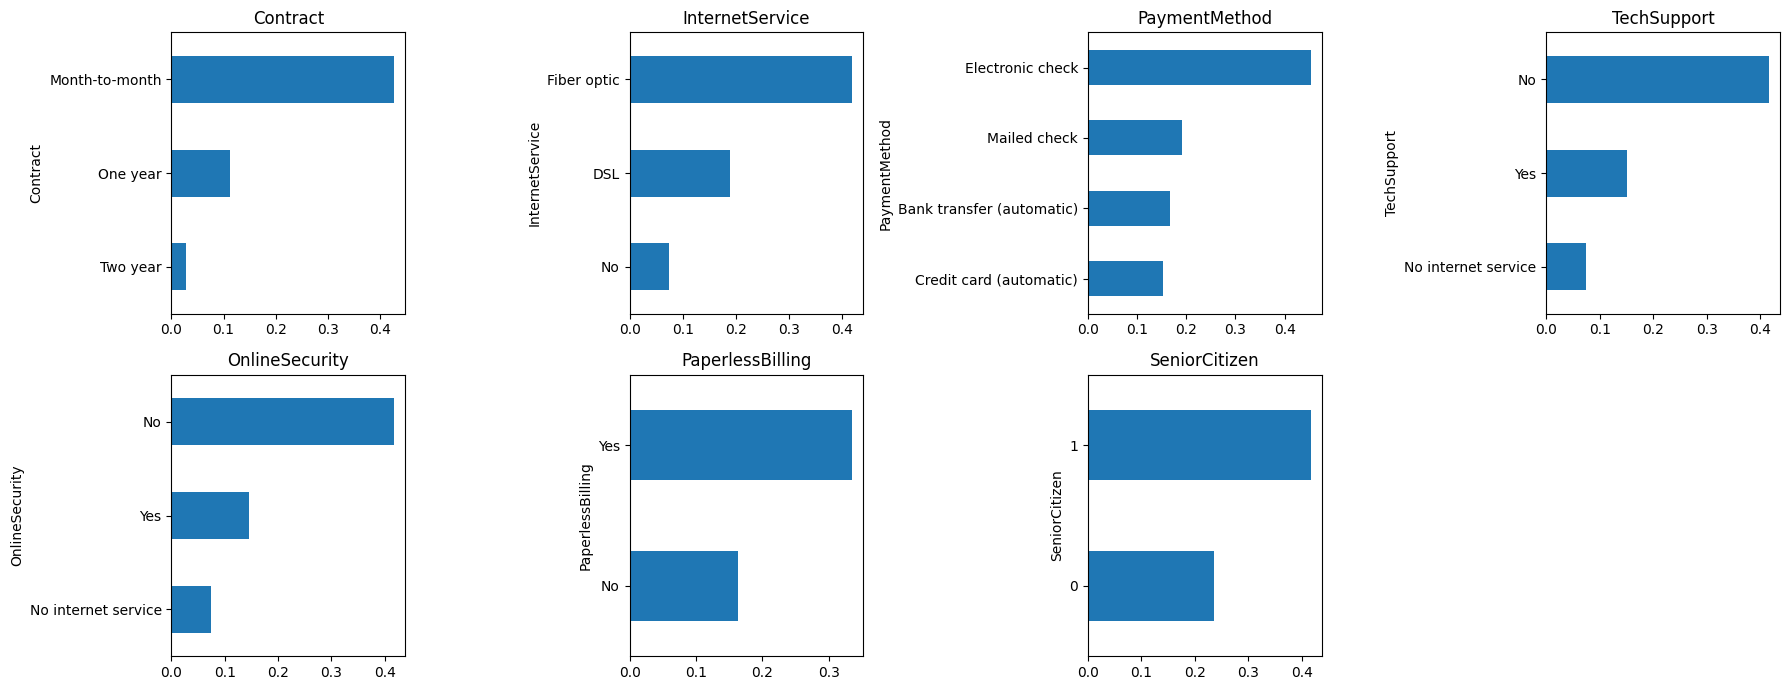

In [2]:
cols = ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport', 'OnlineSecurity', 'PaperlessBilling', 'SeniorCitizen']
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.flat, cols):
    df.groupby(c)['churn'].mean().sort_values().plot.barh(ax=ax, title=c)
axes.flat[-1].axis('off'); plt.tight_layout()

## Tenure and charges

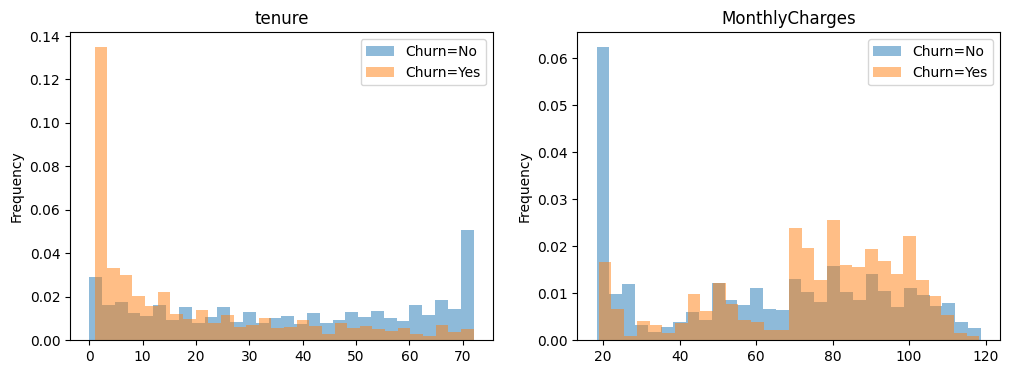

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, c in zip(axes, ['tenure', 'MonthlyCharges']):
    for k, g in df.groupby('Churn'):
        g[c].plot.hist(ax=ax, bins=30, alpha=0.5, density=True, label=f'Churn={k}')
    ax.set_title(c); ax.legend()

## Numeric correlations

In [4]:
df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'churn']].corr().round(2)

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,churn
tenure,1.00,0.25,0.83,0.02,-0.35
MonthlyCharges,0.25,1.00,0.65,0.22,0.19
TotalCharges,0.83,0.65,1.00,0.10,-0.20
SeniorCitizen,0.02,0.22,0.10,1.00,0.15
churn,-0.35,0.19,-0.20,0.15,1.00


## Notes
Write findings here after running; read numbers off the outputs above (no invented metrics). Note `tenure` and `TotalCharges` are strongly collinear — relevant for linear models in Phase 2.